In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Đọc dữ liệu Master Dataset
data_path = os.path.join('..', 'data', 'processed', 'master_gaming_dataset.csv')
df = pd.read_csv(data_path)

# 2. Lọc bỏ các dòng thiếu năm hoặc thiếu doanh thu
df_clean = df.dropna(subset=['release_year', 'Estimated_Revenue_USD']).copy()
df_clean['release_year'] = df_clean['release_year'].astype(int)

# 3. Lọc giai đoạn thị trường hiện đại (2010 - 2024)
df_filtered = df_clean[df_clean['release_year'].between(2010, 2025)]

# 4. Gom nhóm tính tổng doanh thu theo Năm & Nền tảng (Đổi sang đơn vị Triệu USD)
yearly = (
    df_filtered.groupby(['release_year', 'Platform_Category'])['Estimated_Revenue_USD']
    .sum()
    .unstack()
    .fillna(0) / 1e6
)

# 5. Tạo thêm cột Tổng Toàn Ngành
yearly['Total_Global'] = yearly.sum(axis=1)

print("--- DOANH THU THỰC TẾ THEO NĂM (ĐƠN VỊ: TRIỆU USD) ---")
display(yearly.tail(6))

--- DOANH THU THỰC TẾ THEO NĂM (ĐƠN VỊ: TRIỆU USD) ---


Platform_Category,Console,Mobile,PC,Total_Global
release_year,,,,
2020,23883.6,33376.889140,22567.24010,79827.729239
2021,17467.8,27246.527029,21920.19200,66634.519029
2022,17242.4,22343.113802,22878.35765,62463.871452
2023,17607.8,17100.903919,19109.46255,53818.166469
2024,11317.6,13912.059173,30933.99810,56163.657273
2025,11735.5,8302.300278,9531.31635,29569.116628


In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

all_forecasts = []

print("=" * 70)
print("BÁO CÁO ĐÁNH GIÁ OUT-OF-SAMPLE VÀ DỰ BÁO DOANH THU (2025 - 2030)")
print("=" * 70)

for col in ['Total_Global', 'PC', 'Console', 'Mobile']:
    data = yearly[col].dropna()
    X = data.index.values.reshape(-1, 1)
    y = data.values

    n = len(data)
    n_test = max(2, int(np.ceil(n * 0.2)))
    n_train = n - n_test

    # 1. Chia theo trật tự thời gian (Chronological Split)
    X_train, y_train = X[:n_train], y[:n_train]
    X_test, y_test = X[n_train:], y[n_train:]

    # 2. Huấn luyện mô hình kiểm định trên tập Train
    model_test = LinearRegression()
    model_test.fit(X_train, y_train)

    # 3. Đánh giá Out-of-sample trên tập Test
    y_pred_test = model_test.predict(X_test)
    r2_test = r2_score(y_test, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    mae_test = mean_absolute_error(y_test, y_pred_test)

    print(f"\n▶ Nền tảng: {col}")
    print(f"  - Giai đoạn Train: {X_train[0, 0]} - {X_train[-1, 0]}")
    print(f"  - Giai đoạn Test:  {X_test[0, 0]} - {X_test[-1, 0]}")
    print(f"  - R² trên tập Test:   {r2_test:.3f}")
    print(f"  - RMSE trên tập Test: {rmse_test:,.2f}M USD")
    print(f"  - MAE trên tập Test:  {mae_test:,.2f}M USD")

    # In bảng so sánh thực tế vs dự báo trên tập Test
    result_test = pd.DataFrame({
        'Year': X_test.flatten(),
        'Actual': y_test,
        'Predicted': y_pred_test,
        'Error': y_test - y_pred_test
    })
    print(result_test.round(2))

    # -------------------------------------------------------------
    # 4. Huấn luyện lại (Refit) trên TOÀN BỘ dữ liệu để dự báo tương lai
    # -------------------------------------------------------------
    final_model = LinearRegression()
    final_model.fit(X, y)

    future_years = np.arange(2026, 2031).reshape(-1, 1)
    future_predictions = final_model.predict(future_years)

    # Tính Dải dự đoán 95% (95% Prediction Interval)
    y_pred_all = final_model.predict(X)
    s_err = np.sqrt(np.sum((y - y_pred_all)**2) / (n - 2))
    x_mean = np.mean(X)
    sum_sq_diff = np.sum((X - x_mean)**2)
    pi = 1.96 * s_err * np.sqrt(1 + 1/n + (future_years.flatten() - x_mean)**2 / sum_sq_diff)

    # Gom kết quả dự báo của từng nền tảng
    sub_fc = pd.DataFrame({
        'Year': future_years.flatten(),
        'Platform': col,
        'Forecast_Revenue_M_USD': future_predictions.round(2),
        'Lower_Bound_95_PI': np.maximum(0, future_predictions - pi).round(2),
        'Upper_Bound_95_PI': (future_predictions + pi).round(2),
        'Test_R2': round(r2_test, 3),
        'Test_RMSE_M_USD': round(rmse_test, 2)
    })
    all_forecasts.append(sub_fc)

# Gộp kết quả của cả 4 nền tảng thành 1 bảng hoàn chỉnh
df_forecast_all = pd.concat(all_forecasts, ignore_index=True)

print("\n" + "=" * 70)
print("BẢNG TỔNG HỢP DỰ BÁO TẤT CẢ NỀN TẢNG (2025 - 2030)")
print("=" * 70)
display(df_forecast_all)

BÁO CÁO ĐÁNH GIÁ OUT-OF-SAMPLE VÀ DỰ BÁO DOANH THU (2025 - 2030)

▶ Nền tảng: Total_Global
  - Giai đoạn Train: 2010 - 2021
  - Giai đoạn Test:  2022 - 2025
  - R² trên tập Test:   -12.307
  - RMSE trên tập Test: 45,574.57M USD
  - MAE trên tập Test:  42,443.93M USD
   Year    Actual  Predicted     Error
0  2022  62463.87   86810.13 -24346.26
1  2023  53818.17   90901.80 -37083.63
2  2024  56163.66   94993.46 -38829.81
3  2025  29569.12   99085.13 -69516.01

▶ Nền tảng: PC
  - Giai đoạn Train: 2010 - 2021
  - Giai đoạn Test:  2022 - 2025
  - R² trên tập Test:   -1.113
  - RMSE trên tập Test: 11,182.57M USD
  - MAE trên tập Test:  8,347.47M USD
   Year    Actual  Predicted     Error
0  2022  22878.36   25392.23  -2513.88
1  2023  19109.46   26987.51  -7878.05
2  2024  30934.00   28582.79   2351.21
3  2025   9531.32   30178.07 -20646.75

▶ Nền tảng: Console
  - Giai đoạn Train: 2010 - 2021
  - Giai đoạn Test:  2022 - 2025
  - R² trên tập Test:   0.057
  - RMSE trên tập Test: 2,870.91M US

,Year,Platform,Forecast_Revenue_M_USD,Lower_Bound_95_PI,Upper_Bound_95_PI,Test_R2,Test_RMSE_M_USD
0,2026,Total_Global,65383.76,27797.64,102969.89,-12.307,45574.57
1,2027,Total_Global,66277.54,27919.02,104636.06,-12.307,45574.57
2,2028,Total_Global,67171.32,27972.42,106370.21,-12.307,45574.57
3,2029,Total_Global,68065.10,27962.13,108168.07,-12.307,45574.57
4,2030,Total_Global,68958.87,27892.33,110025.42,-12.307,45574.57
5,2026,PC,25125.14,12821.85,37428.43,-1.113,11182.57
6,2027,PC,26149.21,13593.08,38705.34,-1.113,11182.57
7,2028,PC,27173.29,14342.07,40004.50,-1.113,11182.57
8,2029,PC,28197.36,15070.21,41324.51,-1.113,11182.57
9,2030,PC,29221.43,15778.87,42663.99,-1.113,11182.57


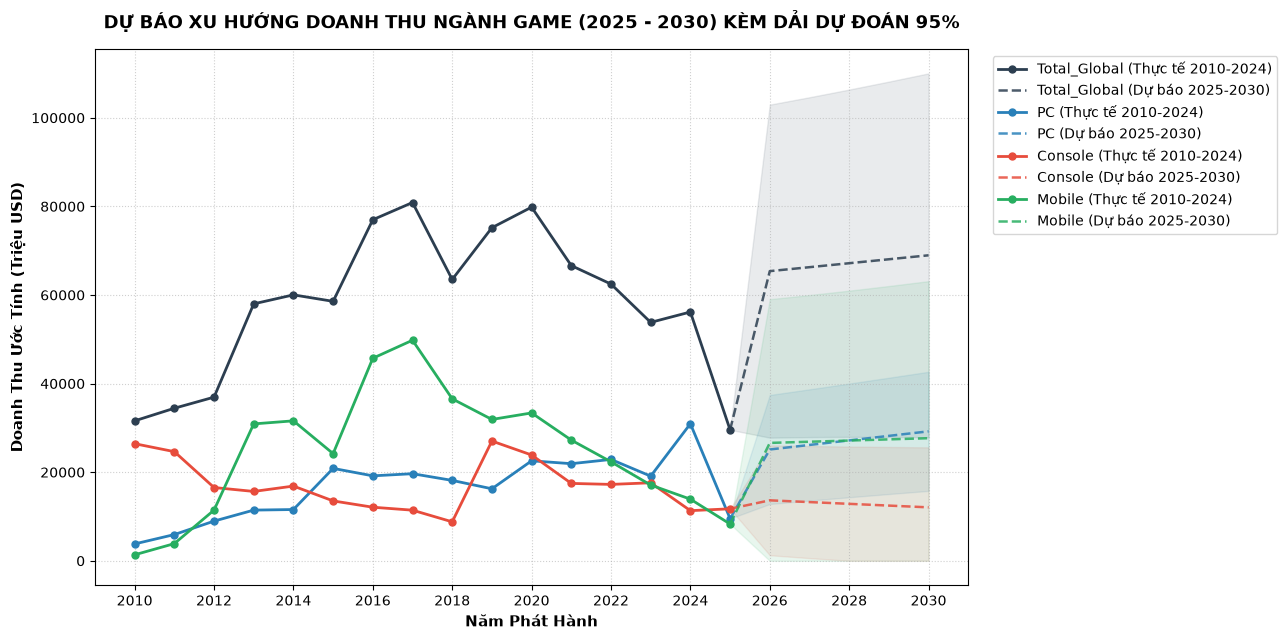

✅ Đã lưu biểu đồ vào: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\visuals\forecast_revenue_2025_2030.png
✅ Đã xuất bảng kết quả dự báo ra: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\data\processed\forecast_results.csv


In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np

# Tự động xác định đường dẫn thư mục gốc an toàn
project_root = os.path.abspath('..') if os.path.exists('../data') else os.path.abspath('.')
visuals_dir = os.path.join(project_root, 'visuals')
os.makedirs(visuals_dir, exist_ok=True)

# 1. Cấu hình màu sắc đặc trưng cho từng nền tảng
colors = {
    'Total_Global': '#2c3e50', # Màu xanh đen đậm (Toàn cầu)
    'PC': '#2980b9',           # Màu xanh Steam
    'Console': '#e74c3c',      # Màu đỏ Console
    'Mobile': '#27ae60'        # Màu xanh lá Mobile
}

plt.figure(figsize=(13, 6.5))

# 2. Vẽ biểu đồ cho từng nền tảng
for col in ['Total_Global', 'PC', 'Console', 'Mobile']:
    sub_fc = df_forecast_all[df_forecast_all['Platform'] == col]
    actual_last_val = yearly[col].loc[2025]
    
    # 2.1. Vẽ đường thực tế (2010 - 2024): Nét liền + dấu tròn
    plt.plot(
        yearly.index, 
        yearly[col], 
        marker='o', 
        markersize=5,
        label=f'{col} (Thực tế 2010-2024)', 
        color=colors[col], 
        linewidth=2
    )
    
    # 2.2. Nối liền mạch: Ghép điểm thực tế năm 2024 vào đầu dãy dự báo (2025 - 2030)
    connect_years = np.concatenate(([2025], sub_fc['Year'].values))
    connect_preds = np.concatenate(([actual_last_val], sub_fc['Forecast_Revenue_M_USD'].values))
    connect_pi_lower = np.concatenate(([actual_last_val], sub_fc['Lower_Bound_95_PI'].values))
    connect_pi_upper = np.concatenate(([actual_last_val], sub_fc['Upper_Bound_95_PI'].values))
    
    # 2.3. Vẽ đường dự báo tương lai: Nét đứt xuất phát từ đúng năm 2024
    plt.plot(
        connect_years, 
        connect_preds, 
        linestyle='--', 
        color=colors[col], 
        alpha=0.85, 
        linewidth=1.8,
        label=f'{col} (Dự báo 2025-2030)'
    )
    
    # 2.4. Vẽ Dải dự đoán 95% (95% Prediction Interval) - Vùng bóng mờ
    plt.fill_between(
        connect_years, 
        connect_pi_lower, 
        connect_pi_upper, 
        color=colors[col], 
        alpha=0.10
    )

# 3. Định dạng tiêu đề & Trục tọa độ chuẩn báo cáo
plt.title('DỰ BÁO XU HƯỚNG DOANH THU NGÀNH GAME (2025 - 2030) KÈM DẢI DỰ ĐOÁN 95%', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Năm Phát Hành', fontsize=11, fontweight='bold')
plt.ylabel('Doanh Thu Ước Tính (Triệu USD)', fontsize=11, fontweight='bold')
plt.xticks(np.arange(2010, 2031, 2)) # Hiển thị mốc 2 năm 1 lần cho thoáng
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()

# 4. Lưu ảnh chất lượng cao vào thư mục visuals
img_path = os.path.join(visuals_dir, 'forecast_revenue_2025_2030.png')
plt.savefig(img_path, dpi=200)
plt.show()
print(f"✅ Đã lưu biểu đồ vào: {img_path}")

# 5. Xuất file CSV kết quả dự báo để nạp lên Power BI
output_csv = os.path.join(project_root, 'data', 'processed', 'forecast_results.csv')
df_forecast_all.to_csv(output_csv, index=False)
print(f"✅ Đã xuất bảng kết quả dự báo ra: {output_csv}")

Đã đọc dữ liệu từ: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\data\processed\master_gaming_dataset.csv
Kích thước dữ liệu: (45828, 11)

Doanh thu theo năm, đơn vị: triệu USD


Platform_Category,PC,Console,Mobile,Total_Global
release_year,,,,
2010,3805.13815,26433.6,1351.936808,31590.674958
2011,5920.04700,24636.0,3878.401332,34434.448332
2012,8957.73640,16540.2,11440.987262,36938.923662
2013,11442.78530,15655.8,30901.289443,57999.874743
2014,11571.39520,16867.2,31592.280837,60030.876037
2015,20858.29160,13516.8,24190.364187,58565.455787
2016,19175.21105,12093.6,45720.151076,76988.962126
2017,19658.75705,11425.8,49786.684956,80871.242006
2018,18145.23490,8793.6,36561.566676,63500.401576



NỀN TẢNG: Total_Global
Train: 2010 - 2021 | Test: 2022 - 2025
R² Test: -12.307
RMSE Test: 45,574.57M USD
MAE Test: 42,443.93M USD


,Year,Actual_M_USD,Predicted_M_USD,Error_M_USD
0,2022,62463.87,86810.13,-24346.26
1,2023,53818.17,90901.80,-37083.63
2,2024,56163.66,94993.46,-38829.81
3,2025,29569.12,99085.13,-69516.01



Dự báo:
2026: 65,383.76M USD
2027: 66,277.54M USD
2028: 67,171.32M USD
2029: 68,065.10M USD
2030: 68,958.87M USD

NỀN TẢNG: PC
Train: 2010 - 2021 | Test: 2022 - 2025
R² Test: -1.113
RMSE Test: 11,182.57M USD
MAE Test: 8,347.47M USD


...

,Year,Actual_M_USD,Predicted_M_USD,Error_M_USD
0,2022,22343.11,45465.56,-23122.45
1,2023,17100.90,48255.75,-31154.84
2,2024,13912.06,51045.93,-37133.87
3,2025,8302.30,53836.11,-45533.81



Dự báo:
2026: 26,610.32M USD
2027: 26,876.16M USD
2028: 27,142.00M USD
2029: 27,407.85M USD
2030: 27,673.69M USD


,Platform,Train_Start,Train_End,Test_Start,Test_End,Test_R2,Test_RMSE_M_USD,Test_MAE_M_USD
0,Total_Global,2010,2021,2022,2025,-12.307,45574.57,42443.93
1,PC,2010,2021,2022,2025,-1.113,11182.57,8347.47
2,Console,2010,2021,2022,2025,0.057,2870.91,2655.48
3,Mobile,2010,2021,2022,2025,-46.811,35204.84,34236.24


,Year,Platform,Forecast_Revenue_M_USD,Lower_Bound_95_PI,Upper_Bound_95_PI,Slope_M_USD_Per_Year,Test_R2,Test_RMSE_M_USD,Test_MAE_M_USD
0,2026,Total_Global,65383.76,24254.06,106513.47,893.78,-12.307,45574.57,42443.93
1,2027,Total_Global,66277.54,24302.62,108252.46,893.78,-12.307,45574.57,42443.93
2,2028,Total_Global,67171.32,24276.79,110065.84,893.78,-12.307,45574.57,42443.93
3,2029,Total_Global,68065.10,24181.26,111948.93,893.78,-12.307,45574.57,42443.93
4,2030,Total_Global,68958.87,24020.62,113897.13,893.78,-12.307,45574.57,42443.93
5,2026,PC,25125.14,11661.90,38588.38,1024.07,-1.113,11182.57,8347.47
6,2027,PC,26149.21,12409.31,39889.12,1024.07,-1.113,11182.57,8347.47
7,2028,PC,27173.29,13132.36,41214.21,1024.07,-1.113,11182.57,8347.47
8,2029,PC,28197.36,13832.60,42562.12,1024.07,-1.113,11182.57,8347.47
9,2030,PC,29221.43,14511.52,43931.35,1024.07,-1.113,11182.57,8347.47


Đã lưu dự báo tại: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\data\processed\forecast_revenue_2026_2030.csv
Đã lưu đánh giá tại: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\data\processed\model_evaluation.csv


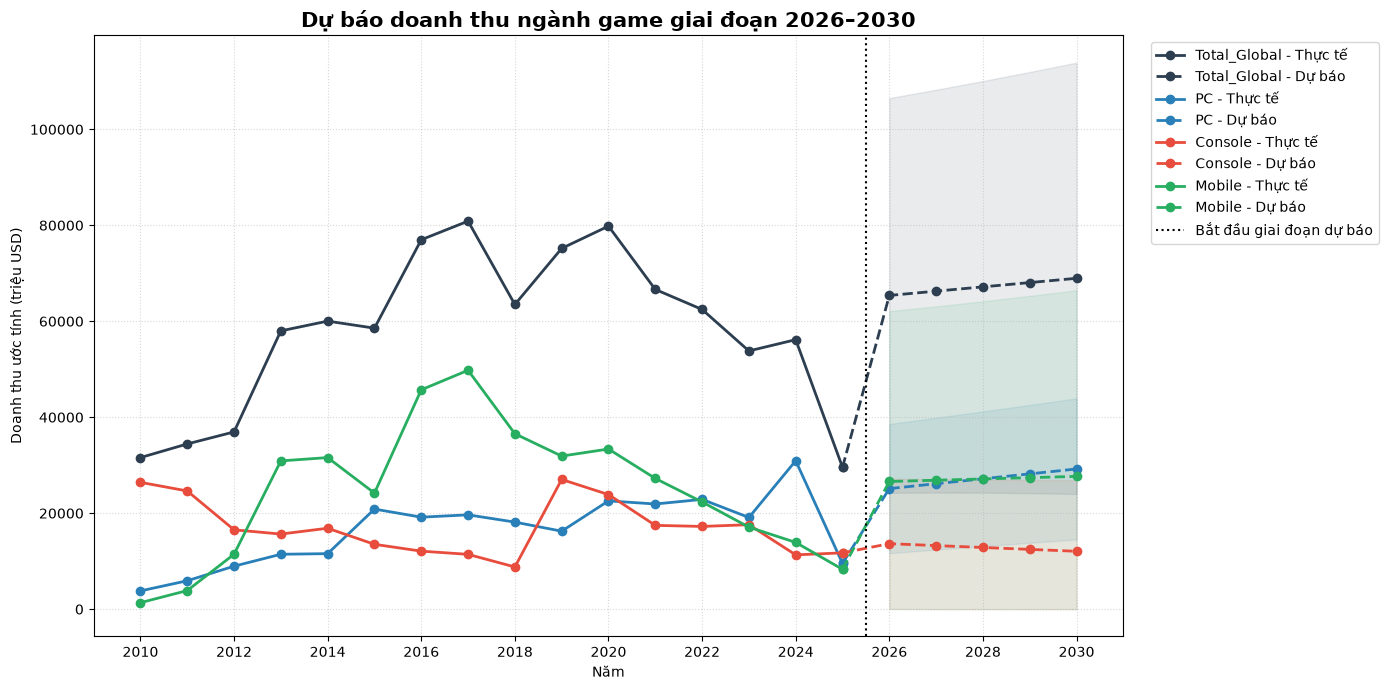

Đã lưu biểu đồ tại: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\visuals\forecast_revenue_2026_2030.png


In [4]:
# ============================================================
# 1. IMPORT THƯ VIỆN
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# ============================================================
# 2. ĐỌC DỮ LIỆU
# ============================================================

possible_paths = [
    Path.cwd() / "data" / "processed" / "master_gaming_dataset.csv",
    Path.cwd().parent / "data" / "processed" / "master_gaming_dataset.csv"
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Không tìm thấy file master_gaming_dataset.csv"
    )

df = pd.read_csv(data_path)

print(f"Đã đọc dữ liệu từ: {data_path}")
print(f"Kích thước dữ liệu: {df.shape}")


# ============================================================
# 3. CHUẨN BỊ DỮ LIỆU THEO NĂM VÀ NỀN TẢNG
# ============================================================

df_clean = df.dropna(
    subset=['release_year', 'Estimated_Revenue_USD']
).copy()

df_clean['release_year'] = (
    df_clean['release_year']
    .astype(int)
)

# Chỉ sử dụng dữ liệu đến năm 2025
df_filtered = df_clean[
    df_clean['release_year'].between(2010, 2025)
].copy()

platforms = ['PC', 'Console', 'Mobile']

yearly = (
    df_filtered
    .groupby(['release_year', 'Platform_Category'])
    ['Estimated_Revenue_USD']
    .sum()
    .unstack(fill_value=0)
    .sort_index()
    / 1_000_000
)

# Đảm bảo luôn có đủ các cột nền tảng
for platform in platforms:
    if platform not in yearly.columns:
        yearly[platform] = 0

# Chỉ giữ các nền tảng cần phân tích
yearly = yearly[platforms]

# Tổng doanh thu toàn thị trường
yearly['Total_Global'] = yearly.sum(axis=1)

print("\nDoanh thu theo năm, đơn vị: triệu USD")
display(yearly)


# ============================================================
# 4. CHIA TRAIN/TEST VÀ DỰ BÁO
# ============================================================

forecast_years = np.arange(2026, 2031)
forecast_records = []
evaluation_records = []

for platform in ['Total_Global', 'PC', 'Console', 'Mobile']:

    data = yearly[platform].dropna()

    X = data.index.to_numpy().reshape(-1, 1)
    y = data.to_numpy()

    n = len(data)

    if n < 6:
        print(f"Bỏ qua {platform}: không đủ dữ liệu.")
        continue

    # Dùng 20% số năm cuối làm tập test
    n_test = max(2, int(np.ceil(n * 0.2)))
    n_test = min(n_test, n - 3)

    n_train = n - n_test

    X_train = X[:n_train]
    y_train = y[:n_train]

    X_test = X[n_train:]
    y_test = y[n_train:]

    # --------------------------------------------------------
    # 4.1. Huấn luyện trên tập train
    # --------------------------------------------------------

    test_model = LinearRegression()
    test_model.fit(X_train, y_train)

    y_test_pred = test_model.predict(X_test)

    r2_test = r2_score(y_test, y_test_pred)
    rmse_test = np.sqrt(
        mean_squared_error(y_test, y_test_pred)
    )
    mae_test = mean_absolute_error(y_test, y_test_pred)

    evaluation_records.append({
        'Platform': platform,
        'Train_Start': int(X_train[0, 0]),
        'Train_End': int(X_train[-1, 0]),
        'Test_Start': int(X_test[0, 0]),
        'Test_End': int(X_test[-1, 0]),
        'Test_R2': round(r2_test, 3),
        'Test_RMSE_M_USD': round(rmse_test, 2),
        'Test_MAE_M_USD': round(mae_test, 2)
    })

    print("\n" + "=" * 65)
    print(f"NỀN TẢNG: {platform}")
    print("=" * 65)
    print(
        f"Train: {X_train[0, 0]} - {X_train[-1, 0]} | "
        f"Test: {X_test[0, 0]} - {X_test[-1, 0]}"
    )
    print(f"R² Test: {r2_test:.3f}")
    print(f"RMSE Test: {rmse_test:,.2f}M USD")
    print(f"MAE Test: {mae_test:,.2f}M USD")

    test_comparison = pd.DataFrame({
        'Year': X_test.flatten(),
        'Actual_M_USD': y_test.round(2),
        'Predicted_M_USD': y_test_pred.round(2),
        'Error_M_USD': (y_test - y_test_pred).round(2)
    })

    display(test_comparison)

    # --------------------------------------------------------
    # 4.2. Huấn luyện lại trên toàn bộ dữ liệu
    # --------------------------------------------------------

    final_model = LinearRegression()
    final_model.fit(X, y)

    future_X = forecast_years.reshape(-1, 1)
    future_pred = final_model.predict(future_X)

    # --------------------------------------------------------
    # 4.3. Prediction Interval 95%
    # --------------------------------------------------------

    historical_pred = final_model.predict(X)
    residuals = y - historical_pred

    degrees_of_freedom = n - 2
    standard_error = np.sqrt(
        np.sum(residuals ** 2) / degrees_of_freedom
    )

    x_mean = np.mean(X)
    sum_squared_diff = np.sum(
        (X.flatten() - x_mean) ** 2
    )

    t_critical = t.ppf(
        0.975,
        df=degrees_of_freedom
    )

    prediction_margin = (
        t_critical
        * standard_error
        * np.sqrt(
            1
            + (1 / n)
            + (
                (forecast_years - x_mean) ** 2
                / sum_squared_diff
            )
        )
    )

    lower_bound = np.maximum(
        0,
        future_pred - prediction_margin
    )

    upper_bound = future_pred + prediction_margin

    # --------------------------------------------------------
    # 4.4. Lưu kết quả dự báo
    # --------------------------------------------------------

    for year, prediction, lower, upper in zip(
        forecast_years,
        future_pred,
        lower_bound,
        upper_bound
    ):
        forecast_records.append({
            'Year': int(year),
            'Platform': platform,
            'Forecast_Revenue_M_USD': round(prediction, 2),
            'Lower_Bound_95_PI': round(lower, 2),
            'Upper_Bound_95_PI': round(upper, 2),
            'Slope_M_USD_Per_Year': round(
                final_model.coef_[0],
                2
            ),
            'Test_R2': round(r2_test, 3),
            'Test_RMSE_M_USD': round(rmse_test, 2),
            'Test_MAE_M_USD': round(mae_test, 2)
        })

    print("\nDự báo:")
    for year, prediction in zip(
        forecast_years,
        future_pred
    ):
        print(
            f"{year}: {prediction:,.2f}M USD"
        )


# ============================================================
# 5. TẠO BẢNG KẾT QUẢ
# ============================================================

df_forecast = pd.DataFrame(forecast_records)
df_evaluation = pd.DataFrame(evaluation_records)

display(df_evaluation)
display(df_forecast)

project_root = data_path.parents[2]
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

forecast_path = output_dir / "forecast_revenue_2026_2030.csv"
evaluation_path = output_dir / "model_evaluation.csv"

df_forecast.to_csv(
    forecast_path,
    index=False,
    encoding='utf-8-sig'
)

df_evaluation.to_csv(
    evaluation_path,
    index=False,
    encoding='utf-8-sig'
)

print(f"Đã lưu dự báo tại: {forecast_path}")
print(f"Đã lưu đánh giá tại: {evaluation_path}")


# ============================================================
# 6. VẼ BIỂU ĐỒ
# ============================================================

visuals_dir = project_root / "visuals"
visuals_dir.mkdir(parents=True, exist_ok=True)

colors = {
    'Total_Global': '#2c3e50',
    'PC': '#2980b9',
    'Console': '#e74c3c',
    'Mobile': '#27ae60'
}

plt.figure(figsize=(14, 7))

for platform in [
    'Total_Global',
    'PC',
    'Console',
    'Mobile'
]:

    historical = yearly[platform]
    forecast = df_forecast[
        df_forecast['Platform'] == platform
    ]

    # Dữ liệu thực tế 2010-2025
    plt.plot(
        historical.index,
        historical.values,
        marker='o',
        linewidth=2,
        color=colors[platform],
        label=f'{platform} - Thực tế'
    )

    # Nối từ năm 2025 sang năm 2026
    connect_years = np.concatenate([
        [2025],
        forecast['Year'].to_numpy()
    ])

    connect_values = np.concatenate([
        [historical.loc[2025]],
        forecast['Forecast_Revenue_M_USD'].to_numpy()
    ])

    plt.plot(
        connect_years,
        connect_values,
        linestyle='--',
        marker='o',
        linewidth=2,
        color=colors[platform],
        label=f'{platform} - Dự báo'
    )

    # Dải dự đoán 95%, chỉ áp dụng cho 2026-2030
    plt.fill_between(
        forecast['Year'],
        forecast['Lower_Bound_95_PI'],
        forecast['Upper_Bound_95_PI'],
        color=colors[platform],
        alpha=0.10
    )

plt.axvline(
    x=2025.5,
    color='black',
    linestyle=':',
    linewidth=1.5,
    label='Bắt đầu giai đoạn dự báo'
)

plt.title(
    'Dự báo doanh thu ngành game giai đoạn 2026–2030',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Năm')
plt.ylabel('Doanh thu ước tính (triệu USD)')
plt.xticks(np.arange(2010, 2031, 2))
plt.grid(linestyle=':', alpha=0.5)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()

chart_path = visuals_dir / "forecast_revenue_2026_2030.png"

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print(f"Đã lưu biểu đồ tại: {chart_path}")

TỶ TRỌNG DOANH THU THEO NỀN TẢNG


Platform_Category,PC,Console,Mobile
release_year,,,
2010,12.05,83.68,4.28
2011,17.19,71.54,11.26
2012,24.25,44.78,30.97
2013,19.73,26.99,53.28
2014,19.28,28.10,52.63
2015,35.62,23.08,41.30
2016,24.91,15.71,59.39
2017,24.31,14.13,61.56
2018,28.57,13.85,57.58


PC: chọn mô hình Linear_Trend | MAE test: 8.93 điểm phần trăm
Console: chọn mô hình Naive_Last_Value | MAE test: 4.65 điểm phần trăm
Mobile: chọn mô hình Naive_Last_Value | MAE test: 10.12 điểm phần trăm

DỰ BÁO TỶ TRỌNG DOANH THU 2026-2030 (%)


,PC,Console,Mobile
Year,,,
2026,49.88,22.48,27.64
2027,50.91,22.02,27.07
2028,51.91,21.57,26.52
2029,52.86,21.15,25.99
2030,53.77,20.74,25.49


,Year,Platform,Forecast_Revenue_Share_Percent,Selected_Model
0,2026,PC,49.88,Linear_Trend
1,2027,PC,50.91,Linear_Trend
2,2028,PC,51.91,Linear_Trend
3,2029,PC,52.86,Linear_Trend
4,2030,PC,53.77,Linear_Trend
5,2026,Console,22.48,Naive_Last_Value
6,2027,Console,22.02,Naive_Last_Value
7,2028,Console,21.57,Naive_Last_Value
8,2029,Console,21.15,Naive_Last_Value
9,2030,Console,20.74,Naive_Last_Value


Đã lưu dự báo: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\data\processed\forecast_platform_share_2026_2030.csv
Đã lưu đánh giá: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\data\processed\platform_share_model_evaluation.csv


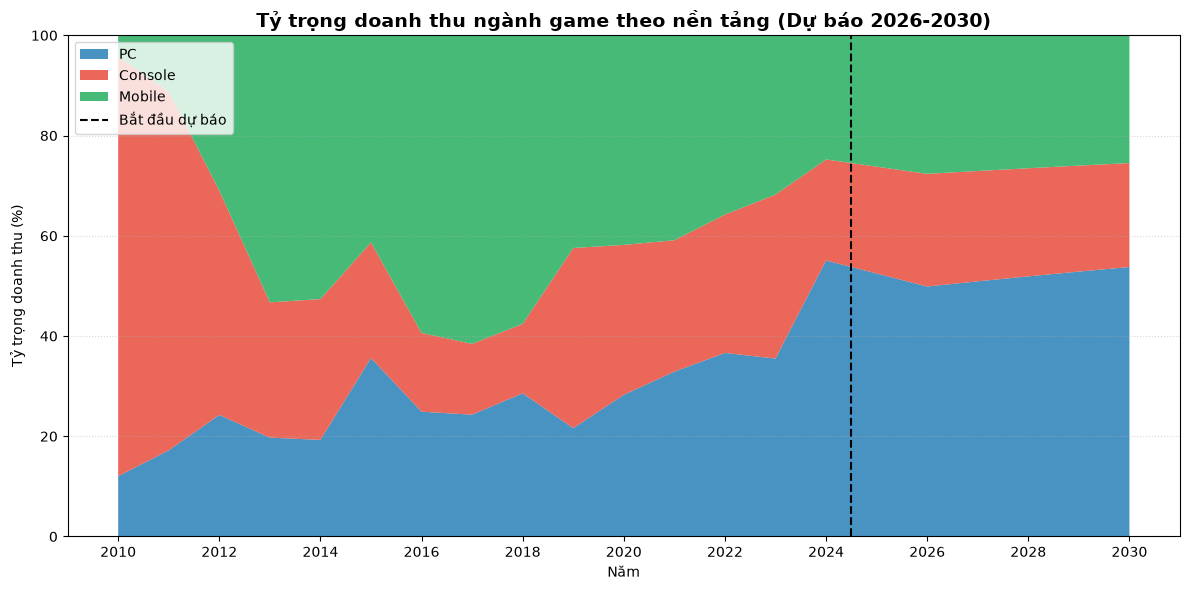

Đã lưu biểu đồ: d:\Documents\TuongTacDuLieu\GAMING INDUSTRY ANALYSIS\Gaming-Market-Industry-Analytics\visuals\forecast_platform_share_2026_2030.png


In [5]:
# ============================================================
# DỰ BÁO TỶ TRỌNG DOANH THU THEO NỀN TẢNG 2026-2030
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


# ============================================================
# 1. ĐỌC DỮ LIỆU
# ============================================================

possible_paths = [
    Path.cwd() / "data" / "processed" / "master_gaming_dataset.csv",
    Path.cwd().parent / "data" / "processed" / "master_gaming_dataset.csv"
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Không tìm thấy master_gaming_dataset.csv"
    )

df = pd.read_csv(data_path)

df = df.dropna(
    subset=[
        'release_year',
        'Estimated_Revenue_USD',
        'Platform_Category'
    ]
).copy()

df['release_year'] = df['release_year'].astype(int)


# ============================================================
# 2. TẠO DOANH THU THEO NĂM VÀ NỀN TẢNG
# ============================================================

# Chỉ dùng dữ liệu đến năm 2024
# Nếu năm 2025 đầy đủ, có thể đổi thành 2025
END_TRAIN_YEAR = 2024

df_filtered = df[
    df['release_year'].between(2010, END_TRAIN_YEAR)
].copy()

platforms = ['PC', 'Console', 'Mobile']

yearly_revenue = (
    df_filtered
    .groupby([
        'release_year',
        'Platform_Category'
    ])['Estimated_Revenue_USD']
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)

# Đảm bảo đủ các nền tảng
for platform in platforms:
    if platform not in yearly_revenue.columns:
        yearly_revenue[platform] = 0

yearly_revenue = yearly_revenue[platforms]

# Tính tổng doanh thu mỗi năm
total_revenue = yearly_revenue.sum(axis=1)

# Tính tỷ trọng doanh thu (%)
yearly_share = yearly_revenue.div(
    total_revenue,
    axis=0
) * 100

yearly_share = yearly_share.dropna()

print("TỶ TRỌNG DOANH THU THEO NỀN TẢNG")
display(yearly_share.round(2))


# ============================================================
# 3. CÁC MÔ HÌNH ỨNG VIÊN
# ============================================================

def predict_linear(x_train, y_train, x_future):
    model = LinearRegression()
    model.fit(x_train, y_train)
    return model.predict(x_future)


def predict_naive(x_train, y_train, x_future):
    # Dự báo bằng giá trị năm gần nhất
    return np.repeat(
        y_train[-1],
        len(x_future)
    )


def predict_moving_average(x_train, y_train, x_future):
    # Dự báo bằng trung bình 3 năm gần nhất
    window = min(3, len(y_train))
    average_value = np.mean(y_train[-window:])

    return np.repeat(
        average_value,
        len(x_future)
    )


candidate_models = {
    'Linear_Trend': predict_linear,
    'Naive_Last_Value': predict_naive,
    'Moving_Average_3Y': predict_moving_average
}


# ============================================================
# 4. CHIA TRAIN/TEST THEO THỜI GIAN
# ============================================================

years = yearly_share.index.to_numpy()
future_years = np.arange(2026, 2031)

# Ba năm cuối làm tập kiểm tra
n_test = 3
n_train = len(years) - n_test

train_years = years[:n_train]
test_years = years[n_train:]

X_train = train_years.reshape(-1, 1)
X_test = test_years.reshape(-1, 1)

evaluation_records = []
selected_models = {}
raw_forecasts = {}

for platform in platforms:

    y = yearly_share[platform].to_numpy()

    y_train = y[:n_train]
    y_test = y[n_train:]

    model_scores = {}

    # Đánh giá từng mô hình trên tập test
    for model_name, model_function in candidate_models.items():

        y_pred_test = model_function(
            X_train,
            y_train,
            X_test
        )

        mae = mean_absolute_error(
            y_test,
            y_pred_test
        )

        model_scores[model_name] = mae

    # Chọn mô hình có MAE nhỏ nhất
    best_model_name = min(
        model_scores,
        key=model_scores.get
    )

    selected_models[platform] = best_model_name

    # Lưu kết quả đánh giá
    for model_name, mae in model_scores.items():
        evaluation_records.append({
            'Platform': platform,
            'Model': model_name,
            'Test_MAE_Percentage_Point': round(mae, 3),
            'Selected': model_name == best_model_name
        })

    # Huấn luyện lại mô hình tốt nhất bằng toàn bộ dữ liệu
    best_model_function = candidate_models[
        best_model_name
    ]

    X_all = years.reshape(-1, 1)

    y_future_pred = best_model_function(
        X_all,
        y,
        future_years.reshape(-1, 1)
    )

    raw_forecasts[platform] = y_future_pred

    print(
        f"{platform}: chọn mô hình "
        f"{best_model_name} | "
        f"MAE test: "
        f"{model_scores[best_model_name]:.2f} điểm phần trăm"
    )


# ============================================================
# 5. CHUẨN HÓA TỔNG TỶ TRỌNG = 100%
# ============================================================

# Không cho tỷ trọng âm
forecast_matrix = np.column_stack([
    raw_forecasts[platform]
    for platform in platforms
])

forecast_matrix = np.maximum(
    forecast_matrix,
    0
)

# Chuẩn hóa từng năm về tổng 100%
row_sums = forecast_matrix.sum(
    axis=1,
    keepdims=True
)

forecast_matrix = (
    forecast_matrix
    / row_sums
    * 100
)


# ============================================================
# 6. TẠO BẢNG KẾT QUẢ
# ============================================================

forecast_share_wide = pd.DataFrame(
    forecast_matrix,
    index=future_years,
    columns=platforms
)

forecast_share_wide.index.name = 'Year'

print("\nDỰ BÁO TỶ TRỌNG DOANH THU 2026-2030 (%)")
display(forecast_share_wide.round(2))

# Chuyển sang dạng dài
forecast_share_long = (
    forecast_share_wide
    .reset_index()
    .melt(
        id_vars='Year',
        var_name='Platform',
        value_name='Forecast_Revenue_Share_Percent'
    )
)

# Thêm mô hình được chọn
forecast_share_long['Selected_Model'] = (
    forecast_share_long['Platform']
    .map(selected_models)
)

display(forecast_share_long.round(2))


# ============================================================
# 7. XUẤT FILE
# ============================================================

project_root = data_path.parents[2]
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

evaluation_df = pd.DataFrame(evaluation_records)

share_forecast_path = (
    output_dir / "forecast_platform_share_2026_2030.csv"
)

evaluation_path = (
    output_dir / "platform_share_model_evaluation.csv"
)

forecast_share_long.to_csv(
    share_forecast_path,
    index=False,
    encoding='utf-8-sig'
)

evaluation_df.to_csv(
    evaluation_path,
    index=False,
    encoding='utf-8-sig'
)

print(f"Đã lưu dự báo: {share_forecast_path}")
print(f"Đã lưu đánh giá: {evaluation_path}")


# ============================================================
# 8. VẼ BIỂU ĐỒ TỶ TRỌNG
# ============================================================

plt.figure(figsize=(12, 6))

# Dữ liệu lịch sử
historical_plot = yearly_share[platforms].copy()

# Dữ liệu dự báo
forecast_plot = forecast_share_wide.copy()

all_share_data = pd.concat([
    historical_plot,
    forecast_plot
])

plt.stackplot(
    all_share_data.index,
    [
        all_share_data['PC'],
        all_share_data['Console'],
        all_share_data['Mobile']
    ],
    labels=['PC', 'Console', 'Mobile'],
    colors=['#2980b9', '#e74c3c', '#27ae60'],
    alpha=0.85
)

plt.axvline(
    x=2024.5,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Bắt đầu dự báo'
)

plt.title(
    'Tỷ trọng doanh thu ngành game theo nền tảng '
    '(Dự báo 2026-2030)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Năm')
plt.ylabel('Tỷ trọng doanh thu (%)')
plt.ylim(0, 100)
plt.xticks(np.arange(2010, 2031, 2))
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()

chart_path = (
    project_root
    / "visuals"
    / "forecast_platform_share_2026_2030.png"
)

chart_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print(f"Đã lưu biểu đồ: {chart_path}")

--- TỶ TRỌNG THỊ PHẦN THỰC TẾ (%) GIAI ĐOẠN 2010 - 2024 ---


Platform_Category,PC,Console,Mobile
release_year,,,
2021,32.9,26.2,40.9
2022,36.6,27.6,35.8
2023,35.5,32.7,31.8
2024,55.1,20.2,24.8
2025,32.2,39.7,28.1



ĐÁNH GIÁ MÔ HÌNH DỰ BÁO TỶ TRỌNG THỊ PHẦN (% MARKET SHARE)

▶ Nền tảng: PC
  - Xu hướng thay đổi: +1.65% mỗi năm
  - Sai số MAE trên tập Test: 8.31%

▶ Nền tảng: Console
  - Xu hướng thay đổi: -2.02% mỗi năm
  - Sai số MAE trên tập Test: 24.72%

▶ Nền tảng: Mobile
  - Xu hướng thay đổi: +0.37% mỗi năm
  - Sai số MAE trên tập Test: 29.42%

DỰ BÁO TỶ TRỌNG THỊ PHẦN 2026 - 2030 (ĐÃ CHUẨN HÓA 100%)


,PC,Console,Mobile
2026,42.1,16.2,41.7
2027,43.7,14.2,42.1
2028,45.4,12.2,42.5
2029,47.0,10.2,42.8
2030,48.7,8.1,43.2


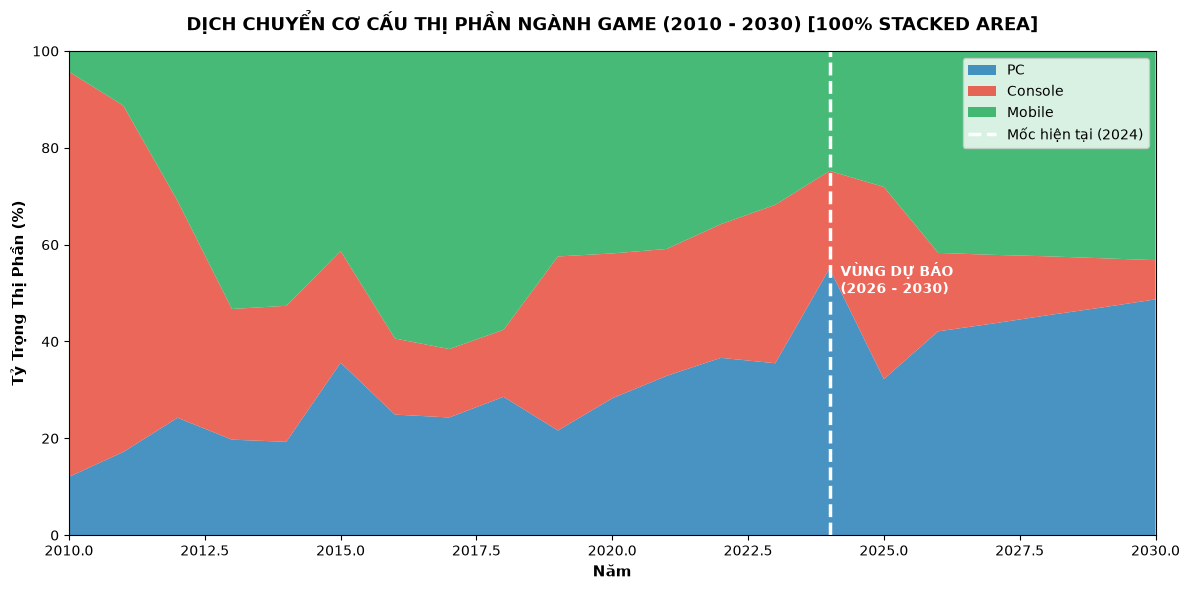

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Tính Tỷ trọng Doanh thu (%) theo từng năm (2010 - 2024)
market_share = (yearly[['PC', 'Console', 'Mobile']].div(yearly[['PC', 'Console', 'Mobile']].sum(axis=1), axis=0) * 100)

print("--- TỶ TRỌNG THỊ PHẦN THỰC TẾ (%) GIAI ĐOẠN 2010 - 2024 ---")
display(market_share.tail(5).round(1))

# 2. Chia Train (2010 - 2021) / Test (2022 - 2024) theo thời gian
X = market_share.index.values.reshape(-1, 1)
n = len(market_share)
n_test = 3 # 3 năm cuối làm test
n_train = n - n_test

X_train, X_test = X[:n_train], X[n_train:]
future_years = np.arange(2026, 2031).reshape(-1, 1)

raw_forecasts = {}

print("\n" + "=" * 65)
print("ĐÁNH GIÁ MÔ HÌNH DỰ BÁO TỶ TRỌNG THỊ PHẦN (% MARKET SHARE)")
print("=" * 65)

for col in ['PC', 'Console', 'Mobile']:
    y = market_share[col].values
    y_train, y_test = y[:n_train], y[n_train:]
    
    # Huấn luyện trên tập Train & Kiểm định trên tập Test
    model_test = LinearRegression().fit(X_train, y_train)
    y_pred_test = model_test.predict(X_test)
    
    mae_test = mean_absolute_error(y_test, y_pred_test)
    
    # 3. Huấn luyện lại trên toàn bộ 15 năm (2010 - 2024)
    final_model = LinearRegression().fit(X, y)
    
    # Dự báo 2026 - 2030 và chặn sàn >= 0%
    preds = np.maximum(0, final_model.predict(future_years))
    raw_forecasts[col] = preds.flatten()
    
    print(f"\n▶ Nền tảng: {col}")
    print(f"  - Xu hướng thay đổi: {final_model.coef_[0]:+5.2f}% mỗi năm")
    print(f"  - Sai số MAE trên tập Test: {mae_test:.2f}%")

# 4. Chuẩn hóa tổng tỷ trọng 3 nền tảng luôn bằng đúng 100.0%
df_fc_raw = pd.DataFrame(raw_forecasts, index=future_years.flatten())
df_fc_normalized = (df_fc_raw.div(df_fc_raw.sum(axis=1), axis=0) * 100).round(1)

print("\n" + "=" * 65)
print("DỰ BÁO TỶ TRỌNG THỊ PHẦN 2026 - 2030 (ĐÃ CHUẨN HÓA 100%)")
print("=" * 65)
display(df_fc_normalized)

# 5. Nối dữ liệu quá khứ và dự báo để vẽ Biểu đồ Chuyển dịch Thị trường (100% Stacked Area)
combined_share = pd.concat([market_share, df_fc_normalized])

plt.figure(figsize=(12, 6))
colors = ['#2980b9', '#e74c3c', '#27ae60'] # PC (Xanh dương), Console (Đỏ), Mobile (Xanh lá)

plt.stackplot(
    combined_share.index, 
    combined_share['PC'], 
    combined_share['Console'], 
    combined_share['Mobile'], 
    labels=['PC', 'Console', 'Mobile'],
    colors=colors, 
    alpha=0.85
)

# Kẻ vạch phân cách giữa Quá khứ và Tương lai dự báo
plt.axvline(x=2024, color='white', linestyle='--', linewidth=2.5, label='Mốc hiện tại (2024)')
plt.text(2024.2, 50, 'VÙNG DỰ BÁO\n(2026 - 2030)', color='white', fontweight='bold', fontsize=10)

plt.title('DỊCH CHUYỂN CƠ CẤU THỊ PHẦN NGÀNH GAME (2010 - 2030) [100% STACKED AREA]', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Năm', fontsize=11, fontweight='bold')
plt.ylabel('Tỷ Trọng Thị Phần (%)', fontsize=11, fontweight='bold')
plt.ylim(0, 100)
plt.xlim(2010, 2030)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()

# Lưu biểu đồ
plt.savefig('../visuals/market_share_transition_2010_2030.png', dpi=200)
plt.show()


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error



df_filtered = df_clean[df_clean['release_year'].between(2010, 2024)]
df_yearly = (
    df_filtered.groupby(['release_year', 'Platform_Category'])['Estimated_Revenue_USD']
    .sum().unstack(fill_value = 0) / 1_000_000
)
df_yearly['Total_Rev'] = df_yearly.sum(axis=1)
print(df_yearly)

columns = [
    'Total_Rev',
    'PC',
    'Console',
    'Mobile'
]
comparison = []
for col in columns:
    data = df_yearly[col].dropna()

    x = data.index.values.reshape(-1, 1)
    y = data.values

    n = len(data)
    train_index = int(n * 0.8)

    x_train = x[:train_index]
    y_train = y[:train_index]

    x_test = x[train_index:]
    y_test = y[train_index:]
    
    linear_model = LinearRegression()
    linear_model.fit(x_train, y_train)

    linear_pred = linear_model.predict(x_test)
    linear_mae = mean_absolute_error(
        y_test,
        linear_pred
    )
    linear_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            linear_pred
        )
    )
    comparison.append({
        'Platform': col,
        'Model': 'Linear_Trend',
        'MAE': linear_mae,
        'RMSE': linear_rmse
    })
    naive_pred = np.repeat(
        y_train[-1],
        len(y_test)
    )
    naive_mae = mean_absolute_error(
        y_test,
        naive_pred
    )
    naive_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            naive_pred
        )
    )
    comparison.append({
        'Platform': col,
        'Model': 'Naive',
        'MAE': naive_mae,
        'RMSE': naive_rmse
    })
comparison_df = pd.DataFrame(comparison)

print(comparison_df)

Platform_Category  Console        Mobile           PC     Total_Rev
release_year                                                       
2010               26433.6   1351.936808   3805.13815  31590.674958
2011               24636.0   3878.401332   5920.04700  34434.448332
2012               16540.2  11440.987262   8957.73640  36938.923662
2013               15655.8  30901.289443  11442.78530  57999.874743
2014               16867.2  31592.280837  11571.39520  60030.876037
2015               13516.8  24190.364187  20858.29160  58565.455787
2016               12093.6  45720.151076  19175.21105  76988.962126
2017               11425.8  49786.684956  19658.75705  80871.242006
2018                8793.6  36561.566676  18145.23490  63500.401576
2019               27030.0  31905.415418  16253.13255  75188.547968
2020               23883.6  33376.889140  22567.24010  79827.729239
2021               17467.8  27246.527029  21920.19200  66634.519029
2022               17242.4  22343.113802  22878.

In [ ]:
# console, mobile và total_rev => Naive
# pc => linear_trend
best_models = (
    comparison_df
    .loc[
        comparison_df
        .groupby('Platform')['MAE']
        .idxmin()
    ]
    .reset_index(drop=True)
)
future_years = np.arange(2025,2031)
forecast_rows = []
for platform in platforms:
    data = df_yearly[platform].dropna()
    X_all = data.index.values.reshape(-1, 1)
    y_all = data.values
    X_future = future_years.reshape(-1, 1)

    selected_model = best_models.loc[
        best_models['Platform'] == platform,
        'Model'
    ].iloc[0]

    if selected_model == 'Linear_Trend':
        model = LinearRegression()
        model.fit(X_all, y_all)
        predictions = model.predict(X_future)
    elif selected_model == 'Naive':
        predictions = np.repeat(
            y_all[-1],
            len(future_years)
        )

    for year, prediction in zip(future_years,predictions):
        forecast_rows.append({
            'year': year,
            'platform': platform,
            'model': selected_model,
            'forecast_revenue_Mil_USD': prediction
        })
forecast_platform = pd.DataFrame(forecast_rows
)
forecast_total = forecast_platform.groupby('year')['forecast_revenue_Mil_USD'].sum()

forecast_total['platform'] = 'Total_Rev'
forecast_total['model'] = 'Combined'

forecast_total = forecast_total[
    [
        'year',
        'platform',
        'model',
        'forecast_revenue_Mil_USD'
    ]
]

forecast_results = pd.concat(
    [
        forecast_platform,
        forecast_total
    ],
    ignore_index=True
)

print(forecast_results)

KeyError: "['year', 'forecast_revenue_Mil_USD'] not in index"